In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

from bokeh.io import output_notebook, show
from bokeh.plotting import figure
from bokeh.models import (
    ColumnDataSource, HoverTool, DataTable, TableColumn,
    Select, RangeSlider, Tabs, Panel, ColorBar, LinearColorMapper
)
from bokeh.layouts import row, column
from bokeh.transform import factor_cmap

output_notebook()

In [2]:
#load dataset
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
#check for null values
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [4]:
#deal with null values by using mean values
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].mean())
df['loan_int_rate'] = df['loan_int_rate'].fillna(df['loan_int_rate'].mean())

df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [5]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_status,0
loan_percent_income,0


In [6]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           32581 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               32581 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [7]:
df['person_home_ownership'].unique()

array(['RENT', 'OWN', 'MORTGAGE', 'OTHER'], dtype=object)

In [8]:
home_ownership_mapping = {
    'RENT': 1,
    'OWN': 2,
    'MORTGAGE': 3,
    'OTHER': 4
}
df['person_home_ownership'] = df['person_home_ownership'].map(home_ownership_mapping)
df['person_home_ownership'].head()

,person_home_ownership
0,1
1,2
2,3
3,1
4,1


In [9]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  int64  
 3   person_emp_length           32581 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               32581 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 3.0+ MB


In [10]:
df['loan_intent'].unique()

array(['PERSONAL', 'EDUCATION', 'MEDICAL', 'VENTURE', 'HOMEIMPROVEMENT',
       'DEBTCONSOLIDATION'], dtype=object)

In [11]:
loan_intent_mapping = {
    'PERSONAL': 1,
    'EDUCATION': 2,
    'MEDICAL': 3,
    'VENTURE': 4,
    'HOMEIMPROVEMENT': 5,
    'DEBTCONSOLIDATION': 6
}
df['loan_intent'] = df['loan_intent'].map(loan_intent_mapping)
df['loan_intent'].head()

,loan_intent
0,1
1,2
2,3
3,3
4,3


In [12]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  int64  
 3   person_emp_length           32581 non-null  float64
 4   loan_intent                 32581 non-null  int64  
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               32581 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(7), object(2)
memory usage: 3.0+ MB


In [13]:
df['loan_grade'].unique()

array(['D', 'B', 'C', 'A', 'E', 'F', 'G'], dtype=object)

In [14]:
loan_grade_mapping = {
    'A': 1,
    'B': 2,
    'C': 3,
    'D': 4,
    'E': 5,
    'F': 6,
    'G': 7
}
df['loan_grade'] = df['loan_grade'].map(loan_grade_mapping)
df['loan_grade'].head()

,loan_grade
0,4
1,2
2,3
3,3
4,3


In [15]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  int64  
 3   person_emp_length           32581 non-null  float64
 4   loan_intent                 32581 non-null  int64  
 5   loan_grade                  32581 non-null  int64  
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               32581 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 3.0+ MB


In [16]:
df['cb_person_default_on_file'].unique()

array(['Y', 'N'], dtype=object)

In [17]:
cb_person_default_on_file_mapping = {
    'Y': 1,
    'N': 0,
}
df['cb_person_default_on_file'] = df['cb_person_default_on_file'].map(cb_person_default_on_file_mapping)
df['cb_person_default_on_file'].head()

,cb_person_default_on_file
0,1
1,0
2,0
3,0
4,1


In [18]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  int64  
 3   person_emp_length           32581 non-null  float64
 4   loan_intent                 32581 non-null  int64  
 5   loan_grade                  32581 non-null  int64  
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               32581 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  int64  
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(9)
memory usage: 3.0 MB


In [19]:
df['loan_status'].unique()

array([1, 0])

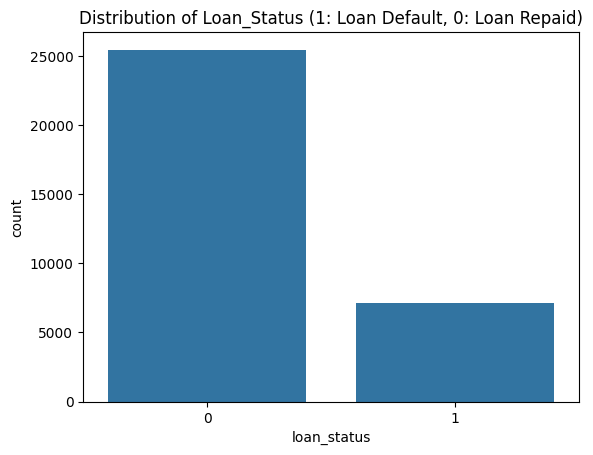

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(x='loan_status', data=df)
plt.title('Distribution of Loan_Status (1: Loan Default, 0: Loan Repaid)')
plt.show()

In [21]:
loan_status_counts = df['loan_status'].value_counts()
loan_status_percentages = df['loan_status'].value_counts(normalize=True) * 100

print("Loan Status Counts:")
print(loan_status_counts)
print("\nLoan Status Percentages:")
print(loan_status_percentages.apply(lambda x: f"{x:.2f}%"))

Loan Status Counts:
loan_status
0    25473
1     7108
Name: count, dtype: int64

Loan Status Percentages:
loan_status
0    78.18%
1    21.82%
Name: proportion, dtype: object


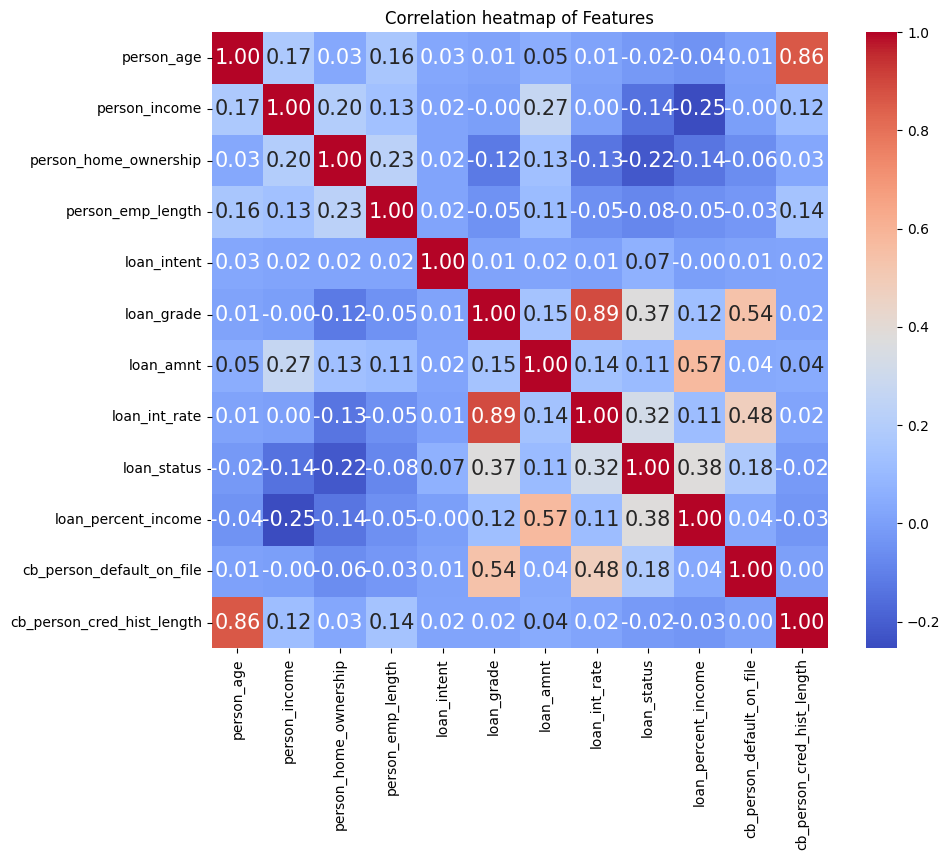

In [22]:
#correlation heatmap
corr_matrix = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cbar = True,  square = True, annot=True, fmt= '.2f',annot_kws={'size': 15}, xticklabels= corr_matrix.columns, yticklabels= corr_matrix.columns, cmap='coolwarm')
plt.title("Correlation heatmap of Features")
plt.show()

# **Sci-kit Learn Pipeline**

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV

# Set transform_output to pandas to get DataFrames
from sklearn import set_config
set_config(transform_output="pandas")

In [24]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [26]:
numeric_preprocessor = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="mean")),
            ("scaler", StandardScaler()),
        ]
    )

In [27]:
preprocessor = ColumnTransformer(
        transformers=[
            ("numerical", numeric_preprocessor, X.columns),
        ],
        remainder="drop" # Drop any columns not listed
    )


In [28]:
model = RandomForestClassifier()

full_pipeline = Pipeline(
        steps=[
            ("preprocess", preprocessor),
            ("classifier", model)
        ]
    )

full_pipeline

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file',
       'cb_person_cred_hist_length'],
      dtype='object'))])),
                ('classifier', RandomForestClassifier())])

In [29]:

print("Fitting basic Scikit-learn pipeline...")
full_pipeline.fit(X_train, y_train)

# Make predictions
y_pred = full_pipeline.predict(X_test)

# --- 7. Evaluate ---
accuracy = accuracy_score(y_test, y_pred)
print(f"\n Pipeline Accuracy: {accuracy:.4f}")
print("\nClassification report:\n", classification_report(y_test, y_pred))

# --- 8. Inspecting the Transformed Data, see how it was fed into the Model ---
print("\nTransformed training data (head):")
# We can access the fitted preprocessor step
preprocessor_fitted = full_pipeline.named_steps["preprocess"]
X_train_transformed = preprocessor_fitted.transform(X_train)
print(X_train_transformed.head())

Fitting basic Scikit-learn pipeline...

 Pipeline Accuracy: 0.9307

Classification report:
               precision    recall  f1-score   support

           0       0.92      0.99      0.96      7613
           1       0.97      0.71      0.82      2162

    accuracy                           0.93      9775
   macro avg       0.95      0.85      0.89      9775
weighted avg       0.93      0.93      0.93      9775


Transformed training data (head):
       numerical__person_age  numerical__person_income  \
12657              -0.429525                  0.003400   
11611              -0.897051                  0.137442   
18223               0.505526                  0.605816   
24772               1.128893                  0.137442   
30770               1.284735                 -0.016629   

       numerical__person_home_ownership  numerical__person_emp_length  \
12657                          1.130730                      1.034961   
11611                          1.130730            

Text(0.5, 36.72222222222221, 'Predicted values')

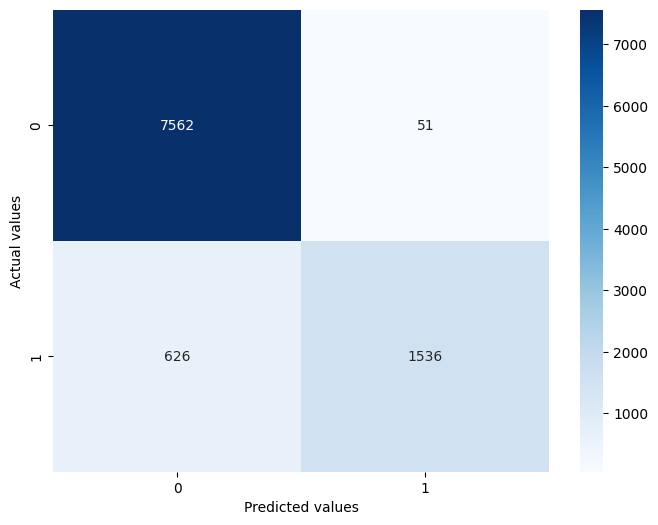

In [30]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.ylabel("Actual values")
plt.xlabel("Predicted values")

In [31]:
from sklearn.metrics import roc_curve, auc
from bokeh.plotting import figure, show
from bokeh.models import ColumnDataSource, HoverTool

# Get probability scores for the positive class (loan_status = 1)
y_pred_proba = full_pipeline.predict_proba(X_test)[:, 1]

# Calculate ROC curve metrics
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Create an ROC curve plot using Bokeh
source_roc = ColumnDataSource(data=dict(fpr=fpr, tpr=tpr, thresholds=thresholds))

p_roc = figure(title=f"Receiver Operating Characteristic (ROC) Curve (AUC = {roc_auc:.2f})",
               x_axis_label='False Positive Rate',
               y_axis_label='True Positive Rate',
               height=350, width=400,
               toolbar_location="below", tools="pan,wheel_zoom,box_zoom,reset,save,hover")

p_roc.line(x='fpr', y='tpr', source=source_roc, line_width=2, line_color='blue', legend_label='ROC Curve')
p_roc.line([0, 1], [0, 1], line_width=1, line_color='black', line_dash='dashed', legend_label='Random Classifier')

# Add hover tool
hover_roc = p_roc.select_one(HoverTool)
hover_roc.tooltips = [
    ("FPR", "@fpr{0.000}"),
    ("TPR", "@tpr{0.000}"),
    ("Threshold", "@thresholds{0.000}"),
]

p_roc.legend.location = "bottom_right"
show(p_roc)

# **Visual 1 – Default rate by loan grade**

In [32]:
from bokeh.models import HoverTool, ColumnDataSource
from bokeh.transform import factor_cmap
from bokeh.palettes import Category10 # Import the palette

# --- Aggregate default rate by loan grade ---
grade_summary = (
    df.groupby("loan_grade")["loan_status"]
      .agg(default_rate="mean", total_loans="size")
      .reset_index()
)

# Convert to percentage
grade_summary["default_rate_pct"] = grade_summary["default_rate"] * 100

# Sort grades in alphabetical order
grade_summary = grade_summary.sort_values("loan_grade")

# Convert loan_grade to string for Bokeh categorical axis
grade_summary["loan_grade"] = grade_summary["loan_grade"].astype(str)

source_grade = ColumnDataSource(grade_summary)

grades = list(grade_summary["loan_grade"])

p_grade = figure(
    x_range=grades,
    height=400,
    width=500,
    title="Default rate by loan grade",
    toolbar_location="below",
    tools="pan,wheel_zoom,box_zoom,reset,save,hover",
)

p_grade.vbar(
    x="loan_grade",
    top="default_rate_pct",
    width=0.7,
    source=source_grade,
    line_color="white",
    fill_color=factor_cmap("loan_grade", Category10[len(grades)], factors=grades), # Use the imported palette
)

p_grade.yaxis.axis_label = "Default rate (%)"
p_grade.xaxis.axis_label = "Loan grade"

hover_grade = p_grade.select_one(HoverTool)
hover_grade.tooltips = [
    ("Grade", "@loan_grade"),
    ("Default rate", "@default_rate_pct{0.0}%"),
    ("Number of loans", "@total_loans"),
]

show(p_grade)


# **Visual 2 – Default Rate by Loan as Percentage of Income**

In [34]:
df['loan_percent_income_bin'] = pd.cut(df['loan_percent_income'],
                                     bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, df['loan_percent_income'].max() + 0.01],
                                     labels=['0-10%', '10-20%', '20-30%', '30-40%', '40-50%', '50%+'],
                                     right=False)

income_pct_summary = (
    df.groupby("loan_percent_income_bin", observed=False)["loan_status"]
      .agg(default_rate="mean", total_loans="size")
      .reset_index()
)

income_pct_summary["default_rate_pct"] = income_pct_summary["default_rate"] * 100

# Sort the bins logically
income_pct_summary["loan_percent_income_bin"] = pd.Categorical(
    income_pct_summary["loan_percent_income_bin"],
    categories=['0-10%', '10-20%', '20-30%', '30-40%', '40-50%', '50%+'],
    ordered=True
)
income_pct_summary = income_pct_summary.sort_values("loan_percent_income_bin")

source_income_pct = ColumnDataSource(income_pct_summary)

bins_labels = list(income_pct_summary["loan_percent_income_bin"].astype(str))

p_income_pct = figure(
    x_range=bins_labels,
    height=400,
    width=700,
    title="Default Rate by Loan as Percentage of Income",
    toolbar_location="below",
    tools="pan,wheel_zoom,box_zoom,reset,save,hover",
)

p_income_pct.vbar(
    x="loan_percent_income_bin",
    top="default_rate_pct",
    width=0.7,
    source=source_income_pct,
    line_color="white",
    fill_color=factor_cmap("loan_percent_income_bin", Category10[len(bins_labels)], factors=bins_labels),
)

p_income_pct.yaxis.axis_label = "Default Rate (%)"
p_income_pct.xaxis.axis_label = "Loan as Percentage of Income"
p_income_pct.xaxis.major_label_orientation = 0.8

hover_income_pct = p_income_pct.select_one(HoverTool)
hover_income_pct.tooltips = [
    ("Income Percentage", "@loan_percent_income_bin"),
    ("Default Rate", "@default_rate_pct{0.0}%",),
    ("Number of Loans", "@total_loans"),
]

show(p_income_pct)

# **Visual 3 - Default rate by cb_person_default_on_file**

In [35]:
# Visual 3 - Default rate by cb_person_default_on_file

default_on_file_summary = (
    df.groupby("cb_person_default_on_file", observed=False)["loan_status"]
      .agg(default_rate="mean", total_loans="size")
      .reset_index()
)

default_on_file_summary["default_rate_pct"] = default_on_file_summary["default_rate"] * 100

# Map back to original labels for better readability
default_on_file_summary['cb_person_default_on_file_label'] = default_on_file_summary['cb_person_default_on_file'].map({0: 'No Previous Default', 1: 'Previous Default'})

source_default_on_file = ColumnDataSource(default_on_file_summary)

labels = list(default_on_file_summary["cb_person_default_on_file_label"])

p_default_on_file = figure(
    x_range=labels,
    height=400,
    width=500,
    title="Default Rate by Previous Default on File",
    toolbar_location="below",
    tools="pan,wheel_zoom,box_zoom,reset,save,hover",
)

p_default_on_file.vbar(
    x="cb_person_default_on_file_label",
    top="default_rate_pct",
    width=0.7,
    source=source_default_on_file,
    line_color="white",
    fill_color=factor_cmap("cb_person_default_on_file_label", Category10[3][:len(labels)], factors=labels),
)

p_default_on_file.yaxis.axis_label = "Default Rate (%)"
p_default_on_file.xaxis.axis_label = "Previous Default on File"

hover_default_on_file = p_default_on_file.select_one(HoverTool)
hover_default_on_file.tooltips = [
    ("Previous Default", "@cb_person_default_on_file_label"),
    ("Default Rate", "@default_rate_pct{0.0}%",),
    ("Number of Loans", "@total_loans"),
]

show(p_default_on_file)

In [36]:
from bokeh.layouts import row, column
from bokeh.models import HoverTool, ColumnDataSource, FactorRange
from bokeh.plotting import figure, show
from bokeh.transform import factor_cmap
from bokeh.palettes import Category10
import pandas as pd

# --- Visual 1: Default rate by loan grade ---
# Ensure the 'loan_grade_mapping' is available if not already in global scope
loan_grade_mapping = {
    'A': 1,
    'B': 2,
    'C': 3,
    'D': 4,
    'E': 5,
    'F': 6,
    'G': 7
}
reverse_loan_grade_mapping = {v: k for k, v in loan_grade_mapping.items()}
df['loan_grade_str'] = df['loan_grade'].map(reverse_loan_grade_mapping)

grade_summary = (
    df.groupby("loan_grade_str")["loan_status"]
      .agg(default_rate="mean", total_loans="size")
      .reset_index()
)

grade_summary["default_rate_pct"] = grade_summary["default_rate"] * 100

# Sort grades based on their original numerical order (A=1, B=2, etc.)
grade_order = sorted(loan_grade_mapping, key=loan_grade_mapping.get)
grade_summary['loan_grade_str'] = pd.Categorical(grade_summary['loan_grade_str'], categories=grade_order, ordered=True)
grade_summary = grade_summary.sort_values("loan_grade_str")

source_grade = ColumnDataSource(grade_summary)

grades = list(grade_summary["loan_grade_str"])

p_grade = figure(
    x_range=grades,
    height=350,
    width=400,
    title="Default Rate by Loan Grade",
    tools="pan,wheel_zoom,box_zoom,reset,save,hover",
    toolbar_location="above"
)

p_grade.vbar(
    x="loan_grade_str",
    top="default_rate_pct",
    width=0.7,
    source=source_grade,
    line_color="white",
    fill_color=factor_cmap("loan_grade_str", Category10[len(grades)], factors=grades),
)

p_grade.yaxis.axis_label = "Default Rate (%)"
p_grade.xaxis.axis_label = "Loan Grade"
p_grade.xgrid.grid_line_color = None
p_grade.y_range.start = 0

hover_grade = p_grade.select_one(HoverTool)
hover_grade.tooltips = [
    ("Grade", "@loan_grade_str"),
    ("Default Rate", "@default_rate_pct{0.0}%",),
    ("Number of Loans", "@total_loans"),
]

# --- Visual 2: Default Rate by Loan as Percentage of Income ---
df['loan_percent_income_bin'] = pd.cut(df['loan_percent_income'],
                                     bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, df['loan_percent_income'].max() + 0.01],
                                     labels=['0-10%', '10-20%', '20-30%', '30-40%', '40-50%', '50%+'],
                                     right=False)

income_pct_summary = (
    df.groupby("loan_percent_income_bin", observed=False)["loan_status"]
      .agg(default_rate="mean", total_loans="size")
      .reset_index()
)

income_pct_summary["default_rate_pct"] = income_pct_summary["default_rate"] * 100

income_pct_summary["loan_percent_income_bin"] = pd.Categorical(
    income_pct_summary["loan_percent_income_bin"],
    categories=['0-10%', '10-20%', '20-30%', '30-40%', '40-50%', '50%+'],
    ordered=True
)
income_pct_summary = income_pct_summary.sort_values("loan_percent_income_bin")

source_income_pct = ColumnDataSource(income_pct_summary)

bins_labels = list(income_pct_summary["loan_percent_income_bin"].astype(str))

p_income_pct = figure(
    x_range=bins_labels,
    height=350,
    width=500,
    title="Default Rate by Loan as Percentage of Income",
    tools="pan,wheel_zoom,box_zoom,reset,save,hover",
    toolbar_location="above"
)

p_income_pct.vbar(
    x="loan_percent_income_bin",
    top="default_rate_pct",
    width=0.7,
    source=source_income_pct,
    line_color="white",
    fill_color=factor_cmap("loan_percent_income_bin", Category10[len(bins_labels)], factors=bins_labels),
)

p_income_pct.yaxis.axis_label = "Default Rate (%)"
p_income_pct.xaxis.axis_label = "Loan as Percentage of Income"
p_income_pct.xaxis.major_label_orientation = 0.8
p_income_pct.xgrid.grid_line_color = None
p_income_pct.y_range.start = 0

hover_income_pct = p_income_pct.select_one(HoverTool)
hover_income_pct.tooltips = [
    ("Income Percentage", "@loan_percent_income_bin"),
    ("Default Rate", "@default_rate_pct{0.0}%",),
    ("Number of Loans", "@total_loans"),
]

# --- Visual 3: Default rate by cb_person_default_on_file ---
default_on_file_summary = (
    df.groupby("cb_person_default_on_file", observed=False)["loan_status"]
      .agg(default_rate="mean", total_loans="size")
      .reset_index()
)

default_on_file_summary["default_rate_pct"] = default_on_file_summary["default_rate"] * 100

default_on_file_summary['cb_person_default_on_file_label'] = default_on_file_summary['cb_person_default_on_file'].map({0: 'No Previous Default', 1: 'Previous Default'})

source_default_on_file = ColumnDataSource(default_on_file_summary)

labels = list(default_on_file_summary["cb_person_default_on_file_label"])

p_default_on_file = figure(
    x_range=labels,
    height=350,
    width=400,
    title="Default Rate by Previous Default on File",
    tools="pan,wheel_zoom,box_zoom,reset,save,hover",
    toolbar_location="above"
)

p_default_on_file.vbar(
    x="cb_person_default_on_file_label",
    top="default_rate_pct",
    width=0.7,
    source=source_default_on_file,
    line_color="white",
    fill_color=factor_cmap("cb_person_default_on_file_label", Category10[3][:len(labels)], factors=labels),
)

p_default_on_file.yaxis.axis_label = "Default Rate (%)"
p_default_on_file.xaxis.axis_label = "Previous Default on File"
p_default_on_file.xgrid.grid_line_color = None
p_default_on_file.y_range.start = 0

hover_default_on_file = p_default_on_file.select_one(HoverTool)
hover_default_on_file.tooltips = [
    ("Previous Default", "@cb_person_default_on_file_label"),
    ("Default Rate", "@default_rate_pct{0.0}%",),
    ("Number of Loans", "@total_loans"),
]

# --- Create the Dashboard Layout ---
dashboard_layout = column(
    row(p_grade, p_default_on_file),
    row(p_income_pct)
)

show(dashboard_layout)
